# Board Games Data Mining
## 6. Pattern Mining

This notebook reorganizes the Pattern Mining experiments:

1. **Transactional preprocessing and semantic discretization**
2. **Frequent / closed / maximal itemsets**
3. **Association rules**
4. **Rule-based classifier for `Rating`**

> Some searches are computationally expensive. They are controlled by `RUN_...` flags so that a normal **Run All** does not generate hundreds of thousands of patterns or rules.

### Packages

We used **PyFIM** (`fim.fpgrowth`) and **jenkspy`**.

If they are missing from the selected notebook kernel, run this once:


In [1]:
%pip install pyfim jenkspy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyfim: filename=pyfim-6.28-cp313-cp313-macosx_26_0_arm64.whl size=181178 sha256=a34eab1027efdbd618c41a88d7d0dabdc5e6fa00d0ce8da66baa7d18461300dd
  Stored in directory: /Users/sarabiiavasco/Library/Caches/pip/wheels/db/88/fb/bc11092c3334c62a0ffa22f8fe44c1cbf7cf64253f7ddbce83
Successfully built pyfim
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jenkspy]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

try:
    import jenkspy
except ImportError as exc:
    raise ImportError(
        "jenkspy is required. Run `%pip install jenkspy` in a notebook cell."
    ) from exc

try:
    from fim import fpgrowth
except ImportError as exc:
    raise ImportError(
        "PyFIM is required. Run `%pip install pyfim` in a notebook cell."
    ) from exc


## 6.0 Data loading

Pattern Mining was performed on the cleaned dataset produced by the data-preparation stage.

The operational filters are retained:

- `YearPublished >= 1949`
- `MaxPlayers <= 30`

With the original cleaned dataset this reduced 20,715 records to **20,306 transactions**.

In [3]:
candidate_paths = [
    Path("DM1_game_dataset_prepared.csv"),
    Path("data/DM1_game_dataset_prepared.csv"),
    Path("DM1_game_dataset_cleaned_4_ml.csv"),
    Path("data/DM1_game_dataset_cleaned_4_ml.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Prepared dataset not found. Put `DM1_game_dataset_prepared.csv` "
        "in the project folder or in a `data/` subfolder."
    )

df = pd.read_csv(DATA_PATH)

# Make boolean columns robust when loaded from CSV as strings.
for col in df.columns:
    if df[col].dtype == object:
        values = set(df[col].dropna().astype(str).str.lower().unique())
        if values and values.issubset({"true", "false"}):
            df[col] = df[col].astype(str).str.lower().map({"true": True, "false": False})

print("Loaded:", DATA_PATH)
print("Rows before Pattern Mining filters:", len(df))

df = df[
    (pd.to_numeric(df["YearPublished"], errors="coerce") >= 1949)
    & (pd.to_numeric(df["MaxPlayers"], errors="coerce") <= 30)
].copy()

print("Rows after filters:", len(df))


Loaded: DM1_game_dataset_prepared.csv
Rows before Pattern Mining filters: 20671
Rows after filters: 20671


## 6.0.1 Semantic discretization

A purely quantile-based discretization was considered too difficult to interpret. The final pipeline therefore combines **domain-driven thresholds** with **Jenks natural breaks**.

Main choices:

- `YearPublished`: old games / 2000–2010 / 2010–2015 / after 2015.
- `GameWeight`: rounded scale, with original 4 and 5 merged.
- `MfgAgeRec`: meaningful age groups.
- `MinPlayers`: only the information “solo playable” is retained.
- `MaxPlayers`: grouped around common player counts.
- `AvgPlaytime`, `NumOwned`, `NumDemand`: 3 Jenks bins (`Low`, `Med`, `High`).
- `Ranking`: 3 Jenks bins after excluding the imputed “unranked” value.
- sparse count variables: presence/absence only.
- boolean attributes: only the `True` item is inserted into a transaction.

We also checked the relation between `NumImplementations` and `IsReimplementation`. `NumImplementations` is retained only for **original games**, so that the item represents an original title that has reimplementations.

In [4]:
RANKING_THR = 0.5056724096930342


def _clean_name(col):
    return (
        str(col)
        .replace(":", "")
        .replace(" ", "_")
        .replace("/", "_")
        .replace("__", "_")
    )


def jenks_3_labels(series, prefix):
    v = pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan)
    v = v.fillna(v.median())

    unique_values = np.unique(v.astype(float))
    k = min(3, len(unique_values))

    if k < 2:
        return pd.Series([f"{prefix}_Low"] * len(v), index=v.index, dtype="object")

    breaks = np.unique(
        np.asarray(
            jenkspy.jenks_breaks(v.to_numpy(dtype=float), n_classes=k),
            dtype=float,
        )
    )

    if len(breaks) < 3:
        return pd.Series([f"{prefix}_Low"] * len(v), index=v.index, dtype="object")

    bins = pd.cut(v, bins=breaks, include_lowest=True, labels=False)
    labels = {0: "Low", 1: "Med", 2: "High"}

    return bins.map(lambda b: f"{prefix}_{labels.get(int(b), 'High')}")


def jenks_3_labels_excluding_value(series, prefix, exclude_value, atol=1e-12):
    v = pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan)

    excluded = np.isclose(v, exclude_value, atol=atol, rtol=0.0)
    fit_values = v[~excluded].dropna()

    out = pd.Series("", index=v.index, dtype="object")

    if fit_values.nunique() < 2:
        out.loc[~excluded] = f"{prefix}_Low"
        return out

    k = min(3, fit_values.nunique())
    breaks = np.unique(
        np.asarray(
            jenkspy.jenks_breaks(fit_values.to_numpy(dtype=float), n_classes=k),
            dtype=float,
        )
    )

    if len(breaks) < 3:
        out.loc[~excluded] = f"{prefix}_Low"
        return out

    non_excluded = v[~excluded].fillna(fit_values.median())
    bins = pd.cut(non_excluded, bins=breaks, include_lowest=True, labels=False)
    labels = {0: "Low", 1: "Med", 2: "High"}

    out.loc[~excluded] = bins.map(
        lambda b: f"{prefix}_{labels.get(int(b), 'High')}"
    )
    return out


def bin_yearpublished(series):
    v = pd.to_numeric(series, errors="coerce").fillna(
        pd.to_numeric(series, errors="coerce").median()
    )
    v = np.rint(v).astype(int)

    out = pd.Series(index=series.index, dtype="object")
    out.loc[v < 2000] = "YP_old_games"
    out.loc[(v >= 2000) & (v <= 2010)] = "YP_2000_2010"
    out.loc[(v > 2010) & (v <= 2015)] = "YP_2010_2015"
    out.loc[v > 2015] = "YP_2015_2020"
    return out


def bin_rating(series):
    v = pd.to_numeric(series, errors="coerce").fillna(
        pd.to_numeric(series, errors="coerce").median()
    )
    v = np.rint(v).astype(int).clip(1, 3)

    return v.map({
        1: "Rating_Low",
        2: "Rating_Med",
        3: "Rating_High",
    })


def bin_minplayers(series):
    v = pd.to_numeric(series, errors="coerce").fillna(
        pd.to_numeric(series, errors="coerce").median()
    )
    v = np.rint(v).astype(int)

    out = pd.Series("", index=series.index, dtype="object")
    out.loc[v == 1] = "SoloPlayable"
    return out


def bin_maxplayers(series):
    v = pd.to_numeric(series, errors="coerce").fillna(
        pd.to_numeric(series, errors="coerce").median()
    )
    v = np.rint(v).astype(int)

    out = pd.Series(index=series.index, dtype="object")
    out.loc[v == 1] = "SoloOnly"
    out.loc[v == 2] = "MaxP_2"
    out.loc[(v >= 3) & (v <= 4)] = "MaxP_3_4"
    out.loc[(v >= 5) & (v <= 6)] = "MaxP_5_6"
    out.loc[v >= 7] = "MaxP_>=7"
    return out


def bin_gameweight(series):
    v = pd.to_numeric(series, errors="coerce").fillna(
        pd.to_numeric(series, errors="coerce").median()
    )
    v = np.rint(v).astype(int).clip(1, 5)

    return v.map(lambda x: f"GW_{x}" if x <= 3 else "GW_4_5")


def bin_mfgagerec(series):
    v = pd.to_numeric(series, errors="coerce").fillna(
        pd.to_numeric(series, errors="coerce").median()
    )
    v = np.rint(v).astype(int)

    out = pd.Series(index=series.index, dtype="object")
    out.loc[v < 8] = "AgeRec_<8"
    out.loc[(v >= 8) & (v <= 10)] = "AgeRec_8_10"
    out.loc[(v >= 11) & (v <= 13)] = "AgeRec_11_13"
    out.loc[v >= 14] = "AgeRec_>=14"
    return out


def present_only_item(series, prefix):
    v = pd.to_numeric(series, errors="coerce").fillna(0)
    out = pd.Series("", index=series.index, dtype="object")
    out.loc[v > 0] = f"{prefix}_Present"
    return out


### Additional consistency check retained from the original experiments

Before changing the representation of `NumImplementations`, we checked the two empirical implications:

- `IsReimplementation → NumImplementations > 0`
- `NumImplementations > 0 → IsReimplementation`

In the original run the first direction had confidence **1.00**, while the reverse direction was about **0.53**. This motivated keeping a special “has implementations” item only for original games.

In [5]:
if {"NumImplementations", "IsReimplementation"}.issubset(df.columns):
    has_impl = pd.to_numeric(df["NumImplementations"], errors="coerce").fillna(0) > 0
    is_reimpl = df["IsReimplementation"].astype(bool)

    conf_reimpl_to_impl = (
        has_impl[is_reimpl].mean() if is_reimpl.sum() else np.nan
    )
    conf_impl_to_reimpl = (
        is_reimpl[has_impl].mean() if has_impl.sum() else np.nan
    )

    print("P(NumImplementations>0 | IsReimplementation=True):",
          round(conf_reimpl_to_impl, 4))
    print("P(IsReimplementation=True | NumImplementations>0):",
          round(conf_impl_to_reimpl, 4))


P(NumImplementations>0 | IsReimplementation=True): 1.0
P(IsReimplementation=True | NumImplementations>0): 0.5201


In [6]:
def prepare_transactions(data):
    selected_columns = [
        "YearPublished",
        "Rating",
        "MinPlayers",
        "MaxPlayers",
        "AvgPlaytime",
        "GameWeight",
        "Ranking",
        "NumOwned",
        "NumDemand",
        "MfgAgeRec",
        "NumExpansions",
        "NumAlternates",
        "NumImplementations",
        "Kickstarted",
        "IsReimplementation",
        "Cat:Thematic",
        "Cat:Strategy",
        "Cat:War",
        "Cat:Family",
        "Cat:CGS",
        "Cat:Abstract",
        "Cat:Party",
        "Cat:Childrens",
    ]

    missing = [c for c in selected_columns if c not in data.columns]
    if missing:
        raise KeyError(f"Missing columns required for Pattern Mining: {missing}")

    dfw = data[selected_columns].copy()

    bool_cols = [
        c for c in dfw.columns
        if pd.api.types.is_bool_dtype(dfw[c])
    ]

    present_only_cols = {
        "NumExpansions",
        "NumAlternates",
        "NumImplementations",
        "MinPlayers",
        "Ranking",
    }

    dfw["YearPublished"] = bin_yearpublished(dfw["YearPublished"])
    dfw["Rating"] = bin_rating(dfw["Rating"])
    dfw["MinPlayers"] = bin_minplayers(dfw["MinPlayers"])
    dfw["MaxPlayers"] = bin_maxplayers(dfw["MaxPlayers"])
    dfw["AvgPlaytime"] = jenks_3_labels(dfw["AvgPlaytime"], "Playtime")
    dfw["GameWeight"] = bin_gameweight(dfw["GameWeight"])
    dfw["Ranking"] = jenks_3_labels_excluding_value(
        dfw["Ranking"],
        prefix="Rank",
        exclude_value=RANKING_THR,
    )
    dfw["NumOwned"] = jenks_3_labels(dfw["NumOwned"], "Owned")
    dfw["NumDemand"] = jenks_3_labels(dfw["NumDemand"], "Demand")
    dfw["MfgAgeRec"] = bin_mfgagerec(dfw["MfgAgeRec"])

    dfw["NumExpansions"] = present_only_item(
        dfw["NumExpansions"], "Exp"
    )
    dfw["NumAlternates"] = present_only_item(
        dfw["NumAlternates"], "Alt"
    )
    dfw["NumImplementations"] = present_only_item(
        dfw["NumImplementations"], "Orig_with_Impl"
    )

    # Keep implementation presence only for original games.
    is_reimplementation = dfw["IsReimplementation"].astype(bool)
    dfw.loc[is_reimplementation, "NumImplementations"] = ""

    # Add column name to non-boolean categorical items.
    for col in dfw.columns:
        if col in bool_cols or col in present_only_cols:
            continue

        clean_col = _clean_name(col)
        dfw[col] = dfw[col].astype(str).map(
            lambda value: f"{value}_{clean_col}"
        )

    # Asymmetric booleans: include only True.
    for col in bool_cols:
        clean_col = _clean_name(col)
        dfw[col] = dfw[col].map(
            lambda value: f"Yes_{clean_col}" if bool(value) else ""
        )

    transactions = dfw.astype(str).values.tolist()
    transactions = [
        [
            item
            for item in row
            if item and item not in {"nan", "None"}
        ]
        for row in transactions
    ]

    return transactions, dfw


X, df_items = prepare_transactions(df)

print("Number of transactions:", len(X))
print("\nExample transaction:")
print(X[0])


Number of transactions: 20671

Example transaction:
['YP_2010_2015_YearPublished', 'Rating_Low_Rating', 'MaxP_3_4_MaxPlayers', 'Playtime_Low_AvgPlaytime', 'GW_2_GameWeight', 'Rank_Med', 'Owned_Med_NumOwned', 'Demand_Med_NumDemand', 'AgeRec_>=14_MfgAgeRec', 'Exp_Present']


In [7]:
# Compact check of the discretized representation.
for col in [
    "YearPublished",
    "Rating",
    "MaxPlayers",
    "AvgPlaytime",
    "GameWeight",
    "Ranking",
    "NumOwned",
    "NumDemand",
    "MfgAgeRec",
]:
    print(f"\n{col}")
    display(
        df_items[col]
        .replace("", np.nan)
        .value_counts(dropna=True)
        .to_frame("count")
    )



YearPublished


,count
YearPublished,
YP_2015_2020_YearPublished,6457
YP_2000_2010_YearPublished,5205
YP_old_games_YearPublished,4535
YP_2010_2015_YearPublished,4474



Rating


,count
Rating,
Rating_Med_Rating,9217
Rating_Low_Rating,6666
Rating_High_Rating,4788



MaxPlayers


...

,count
NumOwned,
Owned_Low_NumOwned,9073
Owned_Med_NumOwned,8241
Owned_High_NumOwned,3357



NumDemand


,count
NumDemand,
Demand_Med_NumDemand,8964
Demand_Low_NumDemand,7733
Demand_High_NumDemand,3974



MfgAgeRec


,count
MfgAgeRec,
AgeRec_8_10_MfgAgeRec,8898
AgeRec_11_13_MfgAgeRec,6377
AgeRec_>=14_MfgAgeRec,2797
AgeRec_<8_MfgAgeRec,2599


# 6.1 Frequent Pattern Extraction

In the final analysis we used **FP-Growth**, after exploratory trials with the available mining approaches.

The principal grid varied:

- minimum support: `1, 2, 3, 4, 5, 7.5, 10, 12.5, 15, 20 %`
- minimum itemset length: `zmin = 1, ..., 8`

For every configuration the number of **frequent**, **closed**, and **maximal** itemsets was compared.

The full grid is useful, but it is disabled by default because it performs 240 mining runs.

,zmin,supp,frequent,closed,maximal
0,1,1.0,23948,23842,7321
1,1,2.0,7636,7636,2827
2,1,3.0,3634,3634,1519
3,1,4.0,2140,2140,951
4,1,5.0,1375,1375,656
...,...,...,...,...,...
75,8,7.5,0,0,0
76,8,10.0,0,0,0
77,8,12.5,0,0,0
78,8,15.0,0,0,0


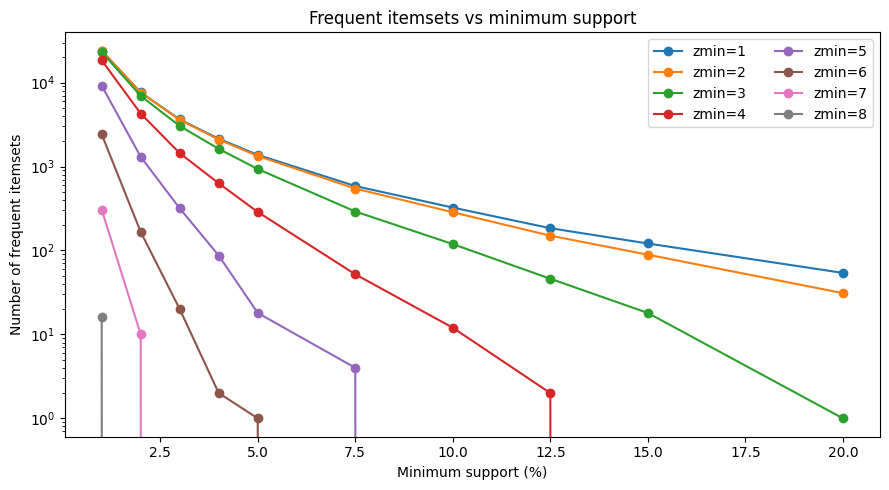

In [8]:
SUPPORT_GRID = [1, 2, 3, 4, 5, 7.5, 10, 12.5, 15, 20]
ZMIN_GRID = list(range(1, 9))

RUN_FREQUENT_PATTERN_GRID = True


def itemset_grid(transactions, target):
    rows = []

    for zmin in ZMIN_GRID:
        for supp in SUPPORT_GRID:
            patterns = fpgrowth(
                transactions,
                target=target,
                supp=supp,
                zmin=zmin,
                report="a",
            )

            rows.append({
                "zmin": zmin,
                "supp": float(supp),
                "n_itemsets": len(patterns),
            })

    return pd.DataFrame(rows)


if RUN_FREQUENT_PATTERN_GRID:
    df_grid_frequent = itemset_grid(X, target="s")
    df_grid_closed = itemset_grid(X, target="c")
    df_grid_maximal = itemset_grid(X, target="m")

    grid_comparison = (
        df_grid_frequent
        .rename(columns={"n_itemsets": "frequent"})
        .merge(
            df_grid_closed.rename(columns={"n_itemsets": "closed"}),
            on=["zmin", "supp"],
        )
        .merge(
            df_grid_maximal.rename(columns={"n_itemsets": "maximal"}),
            on=["zmin", "supp"],
        )
    )

    display(grid_comparison)

    plt.figure(figsize=(9, 5))
    for zmin in ZMIN_GRID:
        sub = df_grid_frequent[
            df_grid_frequent["zmin"] == zmin
        ].sort_values("supp")

        plt.plot(
            sub["supp"],
            sub["n_itemsets"],
            marker="o",
            label=f"zmin={zmin}",
        )

    plt.yscale("log")
    plt.xlabel("Minimum support (%)")
    plt.ylabel("Number of frequent itemsets")
    plt.title("Frequent itemsets vs minimum support")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()
else:
    print(
        "Full frequent/closed/maximal grid skipped. "
        "Set RUN_FREQUENT_PATTERN_GRID = True to reproduce it."
    )


### Main results from the original run

At `min_sup = 1%`, the number of frequent itemsets decreases sharply as the minimum pattern length increases:

| zmin | Frequent itemsets |
|---:|---:|
| 2 | 18,171 |
| 3 | 17,312 |
| 4 | 12,541 |
| 5 | 5,129 |
| 6 | 1,125 |
| 7 | 142 |
| 8 | 8 |

For `min_sup = 1%` and `zmin = 2`, the project obtained:

- **18,171 frequent itemsets**
- **17,636 closed itemsets**
- **6,183 maximal itemsets**

The difference between frequent and closed itemsets rapidly decreases as support increases, showing that most of the extracted frequent patterns are already relatively non-redundant.

The support distribution at `min_sup=1%`, `zmin=2` was strongly concentrated close to the threshold: approximately **70.3%** of patterns had support in `[1%, 2%)`, **24.8%** in `[2%, 5%)`, and only a small fraction reached higher support.

In [9]:
# A single inexpensive run for inspection.
FREQ_SUPP = 1
FREQ_ZMIN = 2

frequent_itemsets = fpgrowth(
    X,
    target="s",
    supp=FREQ_SUPP,
    zmin=FREQ_ZMIN,
    report="aS",
)

df_frequent = pd.DataFrame(
    frequent_itemsets,
    columns=["itemset", "abs_support", "support_pct"],
)

df_frequent["length"] = df_frequent["itemset"].apply(len)
df_frequent = df_frequent.sort_values(
    ["support_pct", "length"],
    ascending=[False, False],
).reset_index(drop=True)

print("Frequent itemsets:", len(df_frequent))
display(df_frequent.head(20))


Frequent itemsets: 23902


,itemset,abs_support,support_pct,length
0,"(Owned_Low_NumOwned, Rank_Med)",7282,35.228097,2
1,"(Rating_Med_Rating, Rank_Med)",6610,31.977166,2
2,"(Playtime_Low_AvgPlaytime, Rank_Med)",6564,31.754632,2
3,"(GW_2_GameWeight, Rank_Med)",6542,31.648203,2
4,"(AgeRec_8_10_MfgAgeRec, Rank_Med)",6474,31.319240,2
5,"(Demand_Med_NumDemand, Rank_Med)",6190,29.945334,2
6,"(Demand_Low_NumDemand, Owned_Low_NumOwned)",6011,29.079387,2
7,"(Demand_Low_NumDemand, Rank_Med)",5989,28.972957,2
8,"(Playtime_Med_AvgPlaytime, Rank_Med)",5652,27.342654,2
9,"(Owned_Med_NumOwned, Rank_Med)",5462,26.423492,2


### Representative patterns retained 

After removing some redundant attributes, three recurring examples were:

| Representative pattern | Support |
|---|---:|
| `Playtime_High`, `CatWar`, `MaxPlayers_2`, `AgeRec_11_13` | 5.604255% |
| `AgeRec_<8`, `GameWeight_1`, `MaxPlayers_3_4`, `Playtime_Low` | 4.161332% |
| `MaxPlayers_5_6`, `Playtime_Med`, `AgeRec_8_10`, `GameWeight_2` | 5.210283% |

A broader recurring structure was the alignment of **Rating, Ranking, demand, ownership, and complexity** across low / medium / high levels. `AvgPlaytime` behaved less uniformly outside the low tier.

# 6.2 Association Rules

Two levels of analysis were used:

1. a broad exploratory extraction with very permissive thresholds to study the distributions of support, confidence, and lift;
2. more selective rule mining for interpretation and prediction.

The broad extraction can generate hundreds of thousands of rules, so it is disabled by default.

Rules retained: 101275


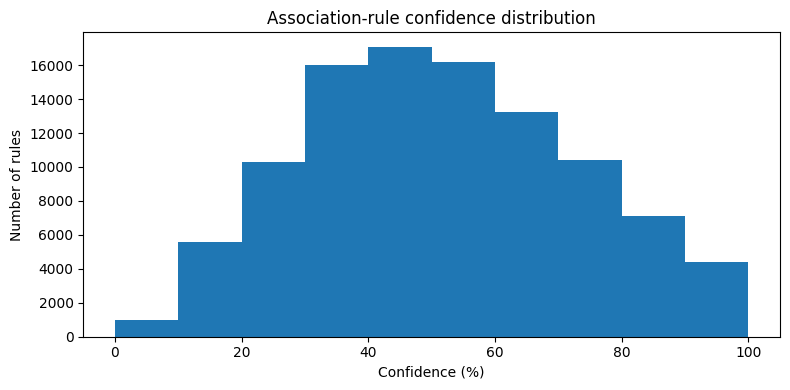

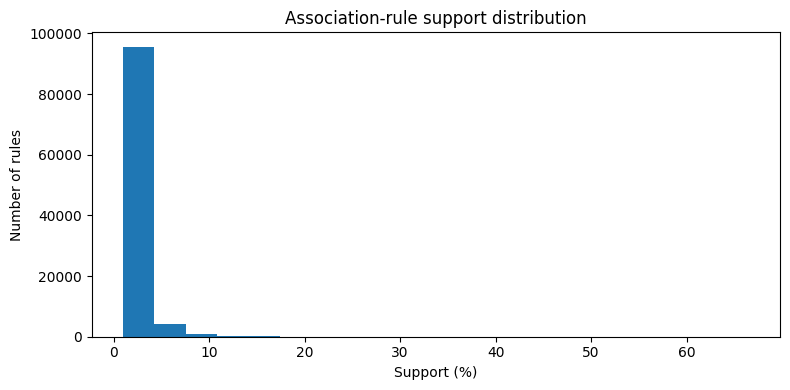

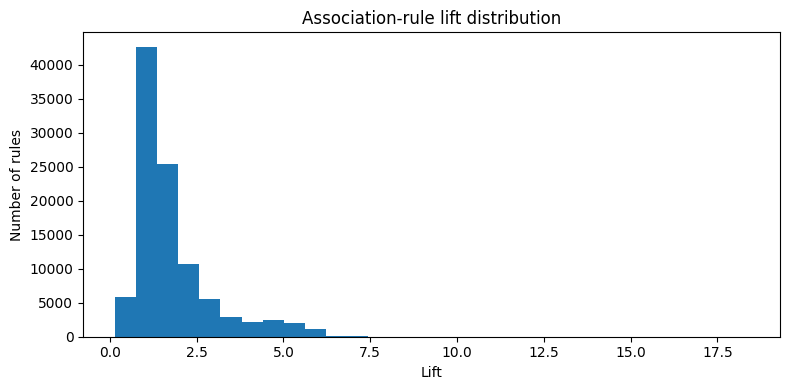

In [10]:
RUN_BROAD_RULE_EXPLORATION = True

if RUN_BROAD_RULE_EXPLORATION:
    broad_rules = fpgrowth(
        X,
        target="r",
        supp=1,
        zmin=1,
        conf=1,
        report="aScl",
    )

    df_rules_broad = pd.DataFrame(
        broad_rules,
        columns=[
            "consequent",
            "antecedent",
            "abs_support",
            "support_pct",
            "confidence",
            "lift",
        ],
    )

    df_rules_broad = df_rules_broad[
        df_rules_broad["support_pct"] >= 1
    ].copy()

    print("Rules retained:", len(df_rules_broad))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(df_rules_broad["confidence"] * 100, bins=np.arange(0, 110, 10))
    ax.set_xlabel("Confidence (%)")
    ax.set_ylabel("Number of rules")
    ax.set_title("Association-rule confidence distribution")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(df_rules_broad["support_pct"], bins=20)
    ax.set_xlabel("Support (%)")
    ax.set_ylabel("Number of rules")
    ax.set_title("Association-rule support distribution")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(df_rules_broad["lift"], bins=30)
    ax.set_xlabel("Lift")
    ax.set_ylabel("Number of rules")
    ax.set_title("Association-rule lift distribution")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Broad rule exploration skipped. "
        "Set RUN_BROAD_RULE_EXPLORATION = True to reproduce it."
    )


### Main exploratory findings

The original analysis found that:

- more than **20%** of the possible rules had confidence at least 70%;
- support was much more restrictive: roughly **74.1%** of rules lay between 1% and 2% support;
- after imposing `confidence >= 70%`, lift ranged approximately from **1.5 to 19**, with mean around **3**;
- almost 80% of those rules still had support between 1% and 2%, about **13.4%** between 2% and 3%, and only **1.64%** exceeded 5% support.

This explains the main trade-off encountered later in the rule-based classifier: high-confidence rules can be very reliable but may cover only a small part of the dataset.

## Additional experiment — which consequents are easiest to predict?
We grouped association rules by the feature appearing in the consequent and compared their confidence distributions.

`NumDemand` was particularly notable, followed by playtime-related rules and `CatWar`. The code below reproduces this analysis with a more manageable confidence threshold.

In [11]:
RUN_TARGET_RULE_ANALYSIS = True

if RUN_TARGET_RULE_ANALYSIS:
    rules_70 = fpgrowth(
        X,
        target="r",
        supp=1,
        zmin=1,
        conf=70,
        report="aScl",
    )

    df_rules_70 = pd.DataFrame(
        rules_70,
        columns=[
            "consequent",
            "antecedent",
            "abs_support",
            "support_pct",
            "confidence",
            "lift",
        ],
    )

    df_rules_70 = df_rules_70[
        df_rules_70["support_pct"] >= 1
    ].copy()

    df_long = df_rules_70.copy()
    df_long["consequent_item"] = df_long["consequent"].astype(str)
    df_long["feature"] = (
        df_long["consequent_item"]
        .str.split("_")
        .str[0]
    )

    confidence_by_feature = (
        df_long.groupby("feature")["confidence"]
        .agg(
            n_rules="count",
            mean="mean",
            median="median",
            max="max",
        )
        .sort_values(["n_rules", "mean"], ascending=[False, False])
    )

    display(confidence_by_feature)
else:
    print(
        "Target/consequent analysis skipped. "
        "Set RUN_TARGET_RULE_ANALYSIS = True to reproduce it."
    )


,n_rules,mean,median,max
feature,,,,
Rank,5057,0.826708,0.819820,0.996283
Demand,3676,0.854006,0.846899,1.000000
Playtime,2878,0.811550,0.803666,0.983264
Owned,2702,0.830822,0.819288,1.000000
Rating,1957,0.797317,0.789137,1.000000
Alt,1366,0.777791,0.771328,0.923954
AgeRec,1055,0.792410,0.781250,0.941704
GW,988,0.808619,0.804000,0.986047
YP,819,0.785311,0.772989,0.965909


### Representative high-lift rules for `AvgPlaytime`

The final report retained the following three examples after requiring rule support greater than 3%:

| Consequent | Antecedent | Confidence | Lift | Support |
|---|---|---:|---:|---:|
| `Playtime_High` | `CatWar`, `old_games`, `GameWeight_3` | 0.8538 | 5.1094 | 3.3636% |
| `Playtime_Low` | `AgeRec_<8`, `GameWeight_1`, `Rating_Med` | 0.9648 | 2.2723 | 3.2404% |
| `Playtime_Med` | `CatStrategy`, `GameWeight_3` | 0.7807 | 1.9120 | 3.8560% |

These examples show how association rules were used not only quantitatively, but also to inspect interpretable relationships between game characteristics.

# 6.3 Rule-Based Classifier

The final experiment exploits the mined rules to predict **`Rating`**.

To avoid leakage:

- the dataset is split first using a **70/30 stratified train/test split**;
- association rules are mined **only on the training transactions**;
- only rules whose consequent is a `Rating_*` item are retained;
- test transactions are evaluated after removing their `Rating` item;
- rules form an ordered **first-match decision list**;
- when no rule matches, the training-set majority class is used.

The original experiments compared rule orderings and found that **descending confidence** worked better than lift-based ordering.

The best reported configuration lowered minimum support to **0.05%** while keeping minimum confidence at **80%**, improving coverage without sacrificing much precision.

In [12]:
RUN_RULE_CLASSIFIER = True

if RUN_RULE_CLASSIFIER:
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import (
        accuracy_score,
        classification_report,
        confusion_matrix,
    )

    RATING_MAP = {
        "Rating_Low_Rating": 1,
        "Rating_Med_Rating": 2,
        "Rating_High_Rating": 3,
    }

    def extract_rating(transaction):
        for item in transaction:
            item = str(item)
            if item in RATING_MAP:
                return item
        return None

    def remove_rating(transaction):
        return {
            str(item)
            for item in transaction
            if "Rating_" not in str(item)
        }

    valid_transactions = []
    valid_labels = []

    for transaction in X:
        rating_item = extract_rating(transaction)
        if rating_item is not None:
            valid_transactions.append(transaction)
            valid_labels.append(RATING_MAP[rating_item])

    X_train, X_test, y_train, y_test = train_test_split(
        valid_transactions,
        valid_labels,
        test_size=0.30,
        stratify=valid_labels,
        random_state=42,
    )

    print("Train size:", len(X_train))
    print("Test size :", len(X_test))

    CLASSIFIER_CONF = 80
    CLASSIFIER_SUPP = 0.05
    CLASSIFIER_ZMIN = 1

    mined_rules = fpgrowth(
        X_train,
        target="r",
        supp=CLASSIFIER_SUPP,
        zmin=CLASSIFIER_ZMIN,
        conf=CLASSIFIER_CONF,
        report="aScl",
    )

    df_rating_rules = pd.DataFrame(
        mined_rules,
        columns=[
            "consequent",
            "antecedent",
            "abs_support",
            "support_pct",
            "confidence",
            "lift",
        ],
    )

    df_rating_rules = df_rating_rules[
        df_rating_rules["consequent"].astype(str).str.contains(
            "Rating_", regex=False
        )
    ].copy()

    df_rating_rules["body_len"] = df_rating_rules["antecedent"].apply(
        lambda body: len(body)
        if isinstance(body, (tuple, list, set))
        else 1
    )

    # Confidence ordering performed best in the original comparisons.
    df_rating_rules = df_rating_rules.sort_values(
        ["confidence", "body_len", "abs_support", "lift"],
        ascending=[False, True, False, False],
    ).reset_index(drop=True)

    compiled_rules = []

    for _, row in df_rating_rules.iterrows():
        consequent = str(row["consequent"])
        prediction = RATING_MAP.get(consequent)

        if prediction is None:
            continue

        body = row["antecedent"]
        body_set = (
            set(body)
            if isinstance(body, (tuple, list, set))
            else {body}
        )
        body_set = {
            str(item)
            for item in body_set
            if "Rating_" not in str(item)
        }

        compiled_rules.append((body_set, prediction))

    majority_class = Counter(y_train).most_common(1)[0][0]

    y_pred = []
    matched = []

    for transaction in X_test:
        features = remove_rating(transaction)
        prediction = None

        for body_set, predicted_class in compiled_rules:
            if body_set.issubset(features):
                prediction = predicted_class
                break

        if prediction is None:
            prediction = majority_class
            matched.append(False)
        else:
            matched.append(True)

        y_pred.append(prediction)

    matched = np.asarray(matched, dtype=bool)

    coverage = matched.mean()
    accuracy = accuracy_score(y_test, y_pred)

    print("\nCoverage:", round(coverage, 3),
          f"({matched.sum()}/{len(matched)})")
    print("Accuracy:", round(accuracy, 3))

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[1, 2, 3]))

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[1, 2, 3],
            target_names=["Low (1)", "Med (2)", "High (3)"],
            digits=3,
        )
    )
else:
    print(
        "Rule-based classifier skipped. "
        "Set RUN_RULE_CLASSIFIER = True to reproduce the expensive mining run."
    )


Train size: 14469
Test size : 6202

Coverage: 0.865 (5365/6202)
Accuracy: 0.67

Confusion matrix:
[[1395  563   42]
 [ 493 1850  422]
 [  40  485  912]]

Classification report:
              precision    recall  f1-score   support

     Low (1)      0.724     0.698     0.710      2000
     Med (2)      0.638     0.669     0.653      2765
    High (3)      0.663     0.635     0.648      1437

    accuracy                          0.670      6202
   macro avg      0.675     0.667     0.671      6202
weighted avg      0.671     0.670     0.671      6202



### Reported test-set results

The final 70/30 experiment reported:

- **Coverage:** 0.831 = 5,062 / 6,092 test instances matched by at least one rule
- **Accuracy:** 0.68

| Rating class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Low (1) | 0.73 | 0.67 | 0.70 | 1,946 |
| Medium (2) | 0.64 | 0.69 | 0.66 | 2,724 |
| High (3) | 0.69 | 0.67 | 0.68 | 1,422 |
| **Macro avg** | **0.69** | **0.68** | **0.68** | 6,092 |
| **Accuracy** |  |  | **0.68** | 6,092 |

Confusion matrix:

```text
[[1317,  612,   17],
 [ 443, 1878,  403],
 [  37,  436,  949]]
```

The main limitation was **coverage** rather than the quality of the highest-confidence rules. Lowering support added more specialized rules; because they were still filtered by high confidence and ordered by confidence, they were rarely applied incorrectly but substantially increased the fraction of covered instances.